# Setup

In [1]:
import os
import json 
import numpy as np
from util import *
import matplotlib.pyplot as plt
%matplotlib ipympl

In [2]:
def get_velocity_and_acceleration(keypoint:np.ndarray, fps:float):
    delta_t = 1/fps # frames/sec
    position = keypoint # point, meters
    velocity = np.gradient(position, delta_t, axis=0)  # vector, m/s
    velocity_magnitude = np.linalg.norm(velocity, axis=1)  # scalar
    acceleration_magnitude = np.gradient(velocity_magnitude, delta_t, axis=0)  # scalar, m/s^2

    return velocity_magnitude, acceleration_magnitude

def get_velocity_and_acceleration_1D(keypoint:np.ndarray, fps:float):
    delta_t = 1/fps
    position = keypoint
    velocity = np.gradient(position, delta_t, axis=0) # scalar
    acceleration = np.gradient(velocity,delta_t, axis=0) # scalar

    return velocity, acceleration

In [15]:
# load preprocessed keypoints
recording_name = 'pq1'
filename_stereo = os.path.join('data', recording_name, recording_name+'_stereo.npz')
# filename_stereo = os.path.join('data', recording_name, recording_name+'_kalman.npz')
filename_stereo_metadata = os.path.join('data', recording_name, recording_name+'_metadata.json')

filename_qualisys = os.path.join('data', recording_name, recording_name+'_qualisys.npz')

for filename in [filename_stereo, filename_stereo_metadata, filename_qualisys]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f'File {filename} does not exist')

    
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
print(f'shape: {stereo_keypoints.shape}')

qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)
print(f'shape: {qualisys_keypoints.shape}')

with open(filename_stereo_metadata) as f:
    stereo_metadata = json.load(f)

loaded data from: data\pq1\pq1_stereo.npz with keys: ['labels', 'keypoints']
shape: (3860, 18, 3)
loaded data from: data\pq1\pq1_qualisys.npz with keys: ['labels', 'keypoints']
shape: (6887, 10, 3)


# Draw trajectories

C:\Users\unger\AppData\Local\Temp\ipykernel_4176\3831735237.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[4].legend()


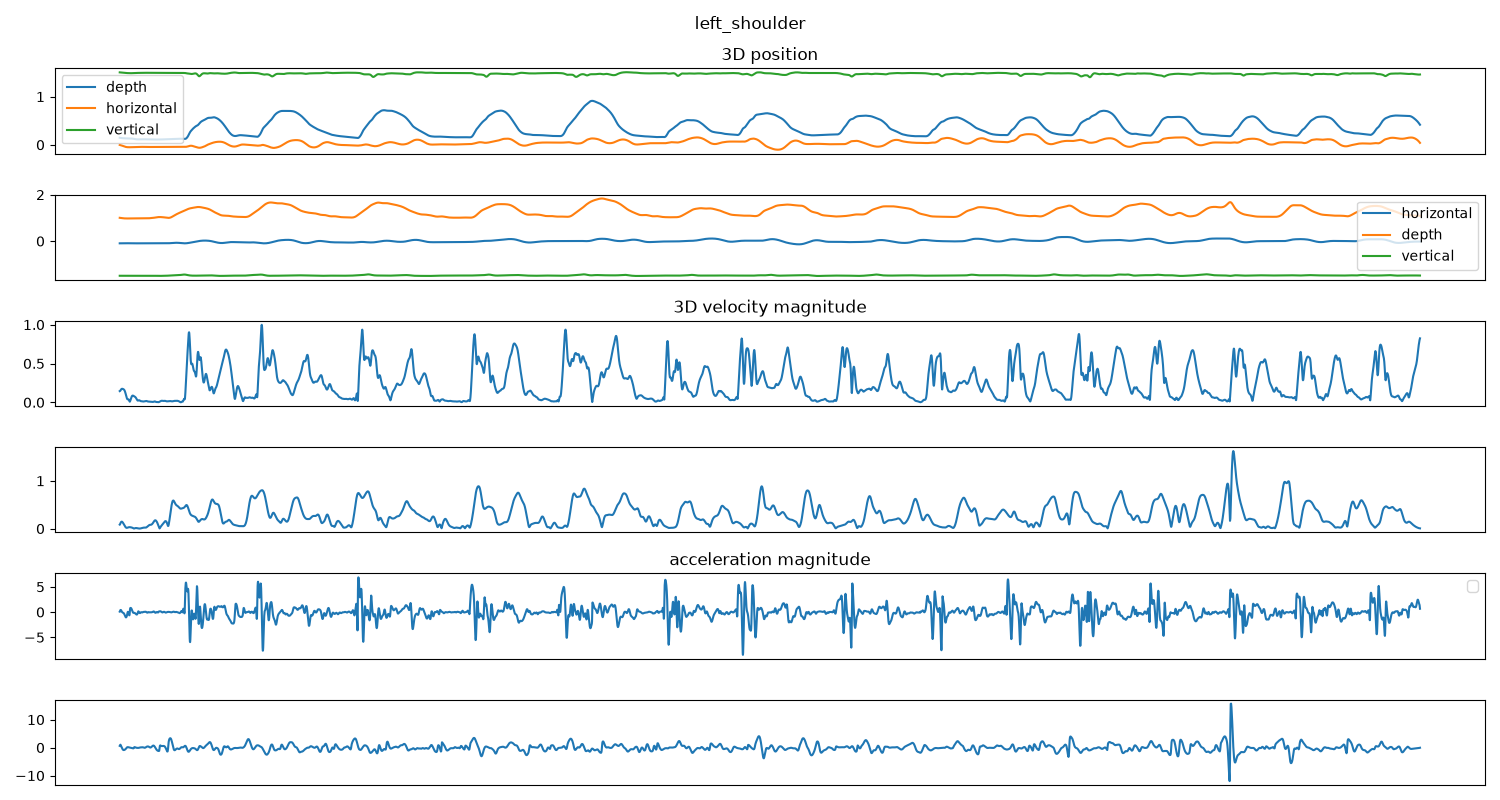

In [16]:
# 3D velocity & acceleration

KPT_NAME = "left_shoulder"
stereo_cut = 300
qualisys_cut = 6300

stereo_kpt = stereo_keypoints[stereo_cut:, stereo_labels.index(KPT_NAME), :]
qualisys_kpt = qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME), :]

stereo_velocity, stereo_acceleration = get_velocity_and_acceleration(
    keypoint=stereo_kpt, fps=stereo_metadata["fps"]
)
qualisys_velocity, qualisys_acceleration = get_velocity_and_acceleration(
    keypoint=qualisys_kpt, fps=100
)


plt.close("all")
fig, axs = plt.subplots(6, 1, figsize=(15, 8))
fig.suptitle(KPT_NAME)

axs[0].set_title("3D position")
axs[0].plot(qualisys_kpt, label=["depth", "horizontal", "vertical"])
axs[0].legend()

axs[1].plot(stereo_kpt, label=["horizontal", "depth", "vertical"])
axs[1].legend()

axs[2].set_title("3D velocity magnitude")
axs[2].plot(qualisys_velocity)

axs[3].plot(stereo_velocity)

axs[4].set_title("acceleration magnitude")
axs[4].plot(qualisys_acceleration)
axs[4].legend()

axs[5].plot(stereo_acceleration, label="'raw'")



for ax in axs[:]:
    ax.set_xticks([])
    # ax.vlines(170, -10,10)
    # ax.vlines(380, -10,10)
    # ax.vlines(690, -10,10)
    # ax.vlines(895, -10,10)
    # ax.vlines(1190, -10,10)
    # ax.vlines(1495, -10,10)
    # ax.vlines(1750, -10,10)
    # ax.vlines(2050, -10,10)
    # ax.vlines(2310, -10,10)
    # ax.vlines(2600, -10,10)
    # ax.vlines(2900, -10,10)
    # ax.vlines(3175, -10,10)
plt.tight_layout()

C:\Users\unger\AppData\Local\Temp\ipykernel_5828\406254649.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()
C:\Users\unger\AppData\Local\Temp\ipykernel_5828\406254649.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[4].legend()


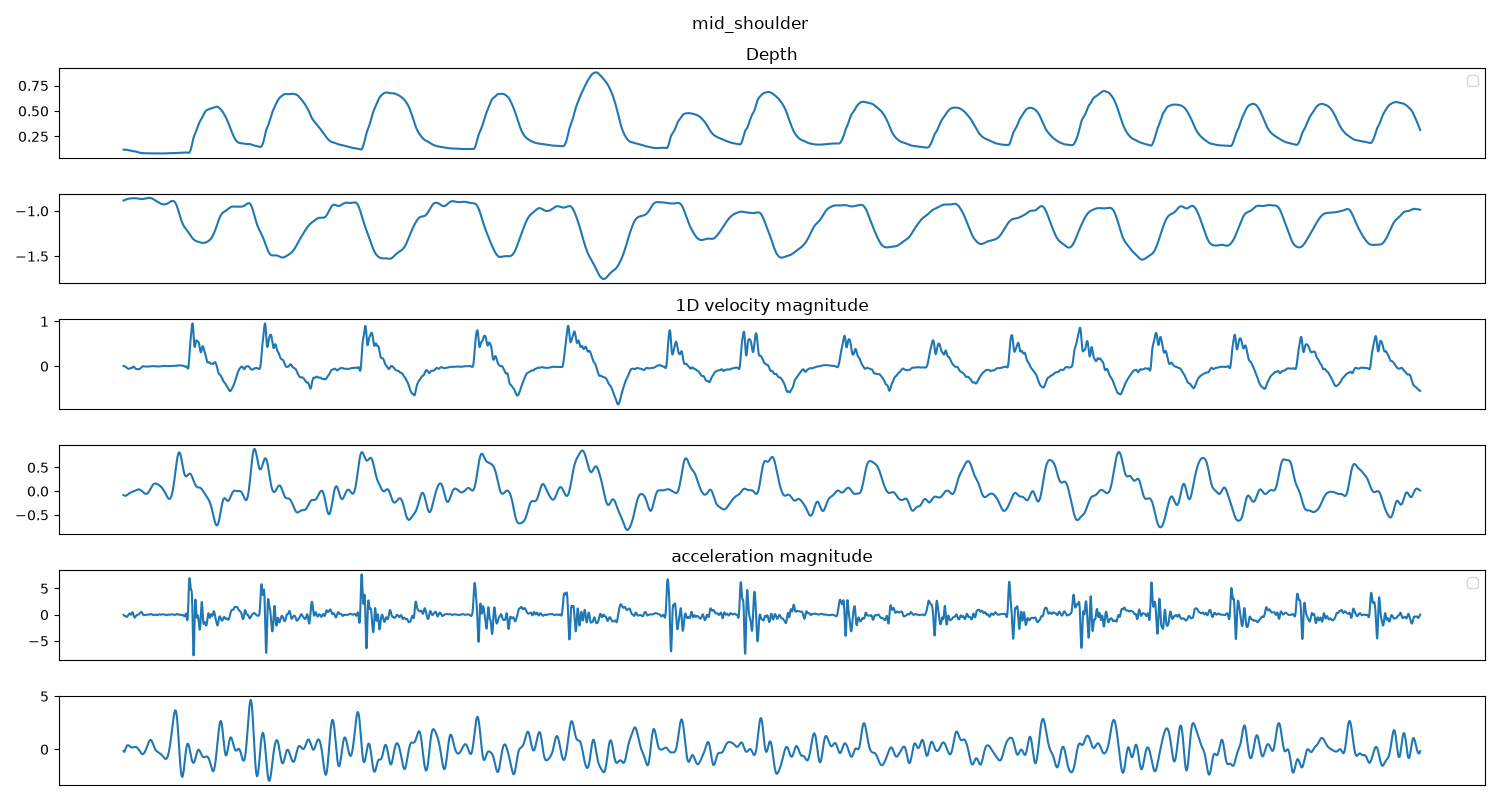

In [13]:
# 1D velocity & acceleration

stereo_kpt = stereo_keypoints[stereo_cut:, stereo_labels.index(KPT_NAME), 1]
qualisys_kpt = qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME), 0]

stereo_velocity, stereo_acceleration = get_velocity_and_acceleration_1D(
    keypoint=stereo_kpt, fps=stereo_metadata["fps"]
)
qualisys_velocity, qualisys_acceleration = get_velocity_and_acceleration_1D(
    keypoint=qualisys_kpt, fps=100
)

from scipy.signal import butter

nyquist = stereo_metadata["fps"] / 2
normal_cutoff = 2 / nyquist
b, a = butter(4, normal_cutoff, btype="low")
filtered_acc_mag = filtfilt(b, a, stereo_acceleration)


plt.close("all")
fig, axs = plt.subplots(6, 1, figsize=(15, 8))
fig.suptitle(KPT_NAME)

axs[0].set_title("Depth")
axs[0].plot(qualisys_kpt)
axs[0].legend()

axs[1].plot(-stereo_kpt)

axs[2].set_title("1D velocity magnitude")
axs[2].plot(qualisys_velocity)

axs[3].plot(stereo_velocity)

axs[4].set_title("acceleration magnitude")
axs[4].plot(qualisys_acceleration)
axs[4].legend()

axs[5].plot(stereo_acceleration, label="'raw'")
# axs[5].plot(-filtered_acc_mag, label="post filtered")


for ax in axs[:]:
    ax.set_xticks([])
plt.tight_layout()